# CNN-1

In [2]:
# baseline，简单的3层CNN
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import random
def set_seed(seed):
   random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed(seed)
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = False
# 调用函数
set_seed(20)

# 数据加载
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)

# 模型定义
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.pool = nn.MaxPool2d(2,2)
        self.fc = nn.Linear(128*4*4, 10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

# 训练
for epoch in range(20):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

torch.save(model.state_dict(), './model/model_baseline.pt')

# 测试
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
print(f'Test Accuracy: {100*correct/total:.2f}%')


Epoch 1, Loss: 2.0505
Epoch 2, Loss: 1.6603
Epoch 3, Loss: 1.4818
Epoch 4, Loss: 1.3696
Epoch 5, Loss: 1.2895
Epoch 6, Loss: 1.2232
Epoch 7, Loss: 1.1622
Epoch 8, Loss: 1.1148
Epoch 9, Loss: 1.0694
Epoch 10, Loss: 1.0212
Epoch 11, Loss: 0.9875
Epoch 12, Loss: 0.9508
Epoch 13, Loss: 0.9228
Epoch 14, Loss: 0.8877
Epoch 15, Loss: 0.8604
Epoch 16, Loss: 0.8340
Epoch 17, Loss: 0.8119
Epoch 18, Loss: 0.7966
Epoch 19, Loss: 0.7715
Epoch 20, Loss: 0.7546
Test Accuracy: 70.11%


# CNN-2

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import random
def set_seed(seed):
   random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed(seed) 
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = False
# 调用函数
set_seed(20)

# 数据加载
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)

# 模型定义
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.pool = nn.MaxPool2d(2,2)
        self.fc = nn.Linear(128*4*4, 10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)  # 每5轮学习率衰减为0.5倍

# 训练
for epoch in range(10):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    scheduler.step()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

torch.save(model.state_dict(), './model/model_opt1.pt')

# 测试
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
print(f'Test Accuracy: {100*correct/total:.2f}%')

Epoch 1, Loss: 1.3986
Epoch 2, Loss: 0.9834
Epoch 3, Loss: 0.8141
Epoch 4, Loss: 0.7115
Epoch 5, Loss: 0.6254
Epoch 6, Loss: 0.5049
Epoch 7, Loss: 0.4610
Epoch 8, Loss: 0.4236
Epoch 9, Loss: 0.3861
Epoch 10, Loss: 0.3505
Test Accuracy: 75.90%


# CNN-3

In [7]:
# opt2, 加入 BatchNorm 和 Dropout
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import random
def set_seed(seed):
   random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed(seed) 
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = False
   torch.backends.cudnn.benchmark = False
set_seed(20)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)

class CNN_BN_Dropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0),-1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN_BN_Dropout().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 训练
for epoch in range(30):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    scheduler.step()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

torch.save(model.state_dict(), './model/model_opt2.pt')

# 测试
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
print(f'Test Accuracy: {100*correct/total:.2f}%')

Epoch 1, Loss: 1.3878
Epoch 2, Loss: 1.0478
Epoch 3, Loss: 0.9266
Epoch 4, Loss: 0.8389
Epoch 5, Loss: 0.7623
Epoch 6, Loss: 0.7058
Epoch 7, Loss: 0.6534
Epoch 8, Loss: 0.6111
Epoch 9, Loss: 0.5685
Epoch 10, Loss: 0.5290
Epoch 11, Loss: 0.4242
Epoch 12, Loss: 0.3861
Epoch 13, Loss: 0.3619
Epoch 14, Loss: 0.3376
Epoch 15, Loss: 0.3173
Epoch 16, Loss: 0.3000
Epoch 17, Loss: 0.2769
Epoch 18, Loss: 0.2645
Epoch 19, Loss: 0.2440
Epoch 20, Loss: 0.2321
Epoch 21, Loss: 0.1789
Epoch 22, Loss: 0.1646
Epoch 23, Loss: 0.1513
Epoch 24, Loss: 0.1450
Epoch 25, Loss: 0.1408
Epoch 26, Loss: 0.1337
Epoch 27, Loss: 0.1263
Epoch 28, Loss: 0.1183
Epoch 29, Loss: 0.1149
Epoch 30, Loss: 0.1115
Test Accuracy: 79.70%


# CNN-4

In [9]:
# opt3, 数据增强
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import random
def set_seed(seed):
   random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed(seed) 
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = False
set_seed(20)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),  # 裁剪
    transforms.RandomHorizontalFlip(p=0.5),  # 翻转
    transforms.RandomRotation(15),  # 旋转
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])


testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)
criterion = nn.CrossEntropyLoss()
trainset_aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_aug)
trainloader_aug = torch.utils.data.DataLoader(trainset_aug, batch_size=128, shuffle=True)

class CNN_BN_Dropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128*4*4,512)
        self.fc2 = nn.Linear(512,10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0),-1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN_BN_Dropout().to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 训练
for epoch in range(30):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader_aug:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    scheduler.step()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader_aug):.4f}")

torch.save(model.state_dict(), './model/model_opt3.pt')

# 测试
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
print(f'Test Accuracy: {100*correct/total:.2f}%')

Epoch 1, Loss: 1.6752
Epoch 2, Loss: 1.3713
Epoch 3, Loss: 1.2459
Epoch 4, Loss: 1.1593
Epoch 5, Loss: 1.0967
Epoch 6, Loss: 1.0532
Epoch 7, Loss: 1.0092
Epoch 8, Loss: 0.9726
Epoch 9, Loss: 0.9550
Epoch 10, Loss: 0.9245
Epoch 11, Loss: 0.8562
Epoch 12, Loss: 0.8346
Epoch 13, Loss: 0.8248
Epoch 14, Loss: 0.8093
Epoch 15, Loss: 0.8004
Epoch 16, Loss: 0.7811
Epoch 17, Loss: 0.7747
Epoch 18, Loss: 0.7594
Epoch 19, Loss: 0.7607
Epoch 20, Loss: 0.7452
Epoch 21, Loss: 0.7146
Epoch 22, Loss: 0.7042
Epoch 23, Loss: 0.7004
Epoch 24, Loss: 0.6975
Epoch 25, Loss: 0.6874
Epoch 26, Loss: 0.6876
Epoch 27, Loss: 0.6841
Epoch 28, Loss: 0.6809
Epoch 29, Loss: 0.6731
Epoch 30, Loss: 0.6758
Test Accuracy: 80.80%


# Evaluation

真实标签:  bird  bird  bird  frog   car horse   car plane  deer   dog
预测标签:  bird plane  bird  frog   car horse   car plane  frog   dog


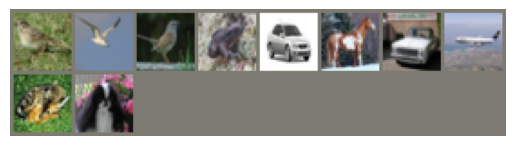

In [13]:
# opt3, 数据增强
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import random
def set_seed(seed):
   random.seed(seed)
   torch.manual_seed(seed)
   torch.cuda.manual_seed(seed)
   torch.cuda.manual_seed_all(seed)
   torch.backends.cudnn.deterministic = True
   torch.backends.cudnn.benchmark = False
# set_seed(20)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),  # 裁剪
    transforms.RandomHorizontalFlip(p=0.5),  # 翻转
    transforms.RandomRotation(15),  # 旋转
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])


testset = torchvision.datasets.CIFAR10(root='data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=True)
criterion = nn.CrossEntropyLoss()
trainset_aug = torchvision.datasets.CIFAR10(root='data', train=True, download=True, transform=transform_aug)
trainloader_aug = torch.utils.data.DataLoader(trainset_aug, batch_size=128, shuffle=True)

class CNN_BN_Dropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128*4*4,512)      
        self.fc2 = nn.Linear(512,10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0),-1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN_BN_Dropout().to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

model = CNN_BN_Dropout().to(device)
model.load_state_dict(torch.load('./model/model_opt3.pt', map_location=device))
model.eval()

classes = ['plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

import matplotlib.pyplot as plt
import numpy as np

# 取一个 batch
dataiter = iter(testloader)
images, labels = next(dataiter)

# 如果使用 GPU，需要转回 CPU 才能显示
images_cpu = images[:10].cpu()
labels_cpu = labels[:10].cpu()

# 推理
with torch.no_grad():
    outputs = model(images.to(device))
    _, predicted = torch.max(outputs, 1)

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3,1,1)
std = torch.tensor([0.2023, 0.1994, 0.2010]).view(3,1,1)

def imshow(img):
    img = (img * std + mean).clamp(0,1)   # 反归一化
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')

imshow(torchvision.utils.make_grid(images_cpu))
print('真实标签:', ' '.join('%5s' % classes[labels_cpu[j]] for j in range(10)))
print('预测标签:', ' '.join('%5s' % classes[predicted.cpu()[j]] for j in range(10)))
plt.show()
